In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from pathlib import Path
from IPython.display import display

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving survey_cleaned.xlsx to survey_cleaned.xlsx


In [4]:
file_name = "survey_cleaned.xlsx"

# Read Excel sheets
excel = pd.ExcelFile(file_name)

print("Available sheets:")
print(excel.sheet_names)

Available sheets:
['Clean_readable', 'Encoded_for_analysis', 'Cleaning_log', 'Missing_summary']


In [5]:
readable = pd.read_excel(
    file_name,
    sheet_name="Clean_readable"
)

df = pd.read_excel(
    file_name,
    sheet_name="Encoded_for_analysis"
)

print("Readable dataset:")
display(readable.head())

print("Encoded dataset:")
display(df.head())

Readable dataset:


,RespondentID,Timestamp,C1,D1,D2,D3,P1,P2,P3,P4,K1,K2,K3,K4,K5,K6,K7,K8,PT1,PT2,PT3,ZT1,ZT2,ZT3,BC1,BC2,BC3,MS1,MS2,MS3,PC1,PC2,PC3,AI1,AI2,AI3,R1,R2,R3,R4,T1,M1,A1,B1,flag_straightliner
0,R001,2026-11-10 08:00:00,"Yes, I agree",Healthcare / clinical,4-7 years,Yes,Wearable monitors,Multi-factor authentication; Zero-trust archit...,Not sure,Not applicable (skipped),Symmetric key brute force,ECDSA P-256,"All n signers, always",Trust only encrypted traffic,Quantum computers can physically damage devices,Higher device battery life,It has no effect,They cannot be implemented in software,2 - Disagree,2 - Disagree,3 - Neutral,3 - Neutral,3 - Neutral,4 - Agree,3 - Neutral,3 - Neutral,2 - Disagree,1 - Strongly disagree,3 - Neutral,3 - Neutral,4 - Agree,4 - Agree,3 - Neutral,3 - Neutral,3 - Neutral,3 - Neutral,Lattice-based (e.g. ML-DSA),5-30 seconds,Depends on the action,Security strength,Patient data breach; Ransomware; Firmware tamp...,Quantum resistance; Compatibility with legacy ...,Access to a full patient record; Change of the...,Cost; Lack of skills,False
1,R061,2026-11-10 08:00:00,"Yes, I agree",Cybersecurity,1-3 years,Yes,Remote patient monitoring; Connected imaging e...,Passwords / PIN; Device certificates (PKI); Ne...,No,Not applicable (skipped),Hash pre-image search,ECDSA P-256,"All n signers, always",Trust everything inside the hospital network,Data captured today may be decrypted once quan...,Faster sensor sampling,It makes keys shorter,They cannot be used with blockchains,4 - Agree,2 - Disagree,3 - Neutral,3 - Neutral,4 - Agree,3 - Neutral,3 - Neutral,4 - Agree,3 - Neutral,2 - Disagree,2 - Disagree,3 - Neutral,4 - Agree,4 - Agree,3 - Neutral,3 - Neutral,3 - Neutral,3 - Neutral,Hybrid classical + post-quantum,1-5 seconds,3-of-5,Low latency,Unauthorized device access; Patient data breac...,Quantum resistance; Compatibility with legacy ...,Firmware update; Access to a full patient reco...,Lack of skills; Regulatory uncertainty,False
2,R097,2026-11-10 08:12:00,"Yes, I agree",Healthcare / clinical,1-3 years,Yes,Wearable monitors; Infusion pumps,Device certificates (PKI); Network segmentation,No,Not applicable (skipped),Integer factorization and discrete logarithm,RSA-3072,Exactly one designated signer,Trust everything inside the hospital network,Wireless signals get weaker,Faster sensor sampling,It makes keys shorter,Larger keys and signatures than ECDSA,3 - Neutral,3 - Neutral,3 - Neutral,4 - Agree,4 - Agree,3 - Neutral,3 - Neutral,4 - Agree,3 - Neutral,2 - Disagree,3 - Neutral,3 - Neutral,4 - Agree,4 - Agree,4 - Agree,4 - Agree,1 - Strongly disagree,3 - Neutral,Lattice-based (e.g. ML-DSA),Under 1 second,Depends on the action,Regulatory compliance,Ransomware; Firmware tampering; Insider misuse,Quantum resistance; Low latency; Auditability ...,Firmware update; Access to a full patient reco...,Cost; Interoperability with legacy devices; Pr...,False
3,R037,2026-11-10 08:12:00,"Yes, I agree",Hospital IT / administration,8 or more years,Yes,Wearable monitors; Infusion pumps; Remote pati...,Passwords / PIN; Multi-factor authentication; ...,Not sure,Not applicable (skipped),Integer factorization and discrete logarithm,ML-DSA (CRYSTALS-Dilithium),At least t of the n signers,"Never trust, always verify",Data captured today may be decrypted once quan...,"Tamper-evident, append-only records","A quadratic speed-up, so longer keys (e.g. AES...",Larger keys and signatures than ECDSA,4 - Agree,5 - Strongly agree,4 - Agree,4 - Agree,4 - Agree,3 - Neutral,4 - Agree,3 - Neutral,4 - Agree,3 - Neutral,4 - Agree,4 - Agree,5 - Strongly agree,2 - Disagree,4 - Agree,4 - Agree,3 - Neutral,3 - Neutral,Multivariate,1-5 seconds,3-of-5,Low energy use,Unauthorized device access; Quantum attack on ...,Quantum resistance; Low latency; Flexible t-of...,Firmware update; Emergency override (break-gla...,Lack of skills; Regulatory uncertainty; Perfor...,False
4,R073,2026-11-10 08:24:00,"Yes, I agree",Blockchain / software development,Less than 1 year,Yes,Impla

Encoded dataset:


,RespondentID,Timestamp,PT1,PT2,PT3,ZT1,ZT2,ZT3,BC1,BC2,BC3,MS1,MS2,MS3,PC1,PC2,PC3,AI1,AI2,AI3,D2_ordinal,K1_correct,K2_correct,K3_correct,K4_correct,K5_correct,K6_correct,K7_correct,K8_correct,Knowledge_score,Knowledge_pct,P1__Wearable_monitors,P1__Infusion_pumps,P1__Implantable_devices,P1__Remote_patient_monitoring,P1__Connected_imaging_equipment,P1__Smart_hospital_beds,P2__Passwords_PIN,P2__Device_certificates_PKI,P2__Network_segmentation,P2__Multi_factor_authentication,P2__Blockchain_based_logging,P2__Zero_trust_architecture,P2__Post_quantum_cryptography,P2__None_of_these,P4__liboqs_Open_Quantum_Safe,P4__PQClean,P4__Bouncy_Castle_PQC,P4__CIRCL_Cloudflare,P4__Vendor_commercial_toolkit,T1__Unauthorized_device_access,T1__Patient_data_breach,T1__Ransomware,T1__Firmware_tampering,T1__Denial_of_service,T1__Quantum_attack_on_cryptograp,T1__Insider_misuse,M1__Quantum_resistance,M1__Low_latency,M1__Small_signature_size,M1__Flexible_t_of_n_thresholds,M1__Revocation_of_compromised_si,M1__Auditability_on_blockchain,M1__Compatibility_with_legacy_de,A1__Firmware_update,A1__Access_to_a_full_patient_rec,A1__Change_of_device_configurati,A1__Emergency_override_break_gla,A1__Adding_a_new_device_to_the_n,A1__Change_of_therapy_parameters,B1__Cost,B1__Lack_of_skills,B1__Regulatory_uncertainty,B1__Interoperability_with_legacy,B1__Performance_limits,B1__Lack_of_standards,B1__Privacy_concerns,D1__Academic / student,D1__Blockchain / software development,D1__Cybersecurity,D1__Healthcare / clinical,D1__Hospital IT / administration,D1__Medical-device engineering,D3__No,D3__Yes,P3__No,P3__Not applicable (skipped),P3__Not sure,P3__Yes,R1__Code-based,R1__Hash-based (e.g. SLH-DSA),R1__Hybrid classical + post-quantum,R1__Lattice-based (e.g. ML-DSA),R1__Multivariate,R1__Not sure,R2__1-5 seconds,R2__30 seconds - 2 minutes,R2__5-30 seconds,R2__More than 2 minutes,R2__Under 1 second,R3__2-of-3,R3__3-of-5,R3__All signers,R3__Depends on the action,R3__Simple majority,R4__Interoperability with existing devices,R4__Low energy use,R4__Low implementation cost,R4__Low latency,R4__Regulatory compliance,R4__Security strength,PT_score,ZT_score,BC_score,MS_score,PC_score,AI_score
0,R001,2026-11-10 08:00:00,2,2,3,3,3,4,3,3,2,1,3,3,4,4,3,3,3,3,2,0,0,0,0,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0,1,1,1,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,2.333333,3.333333,2.666667,2.333333,3.666667,3.000000
1,R061,2026-11-10 08:00:00,4,2,3,3,4,3,3,4,3,2,2,3,4,4,3,3,3,3,1,0,0,0,0,1,0,0,0,1,12.5,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1,1,0,1,0,0,1,1,0,0,0,0,0,1,1,1,1,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,3.000000,3.333333,3.333333,2.333333,3.666667,3.000000
2,R097,2026-11-10 08:12:00,3,3,3,4,4,3,3,4,3,2,3,3,4,4,4,4,1,3,1,1,0,0,0,0,0,0,1,2,25.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0,0,1,1,0,0,1,1,1,0,0,0,1,0,1,1,1,1,1,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,3.000000,3.666667,3.333333,2.666667,4.000000,2.666667
3,R037,2026-11-10 08:12:00,4,5,4,4,4,3,4,3,4,3,4,4,5,2,4,4,3,3,3,1,1,1,1,1,1,1,1,8,100.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1,0,0,0,0,1,1,1,1,0,1,0,1,1,1,0,0,1,1,1,0,1,1,0,1,1,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,4.333333,3.666667,3.666667,3.666667,3.666667,3.333333
4,R073,2026-11-10 08:24:00,3,3,4,4,5,3,3,3,3,4,4,4,3,4,2,5,4,4,0,1,1,0,1,1,1,0,0,5,62.5,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,1,1,1,0,0,1,1,1,1,0,1,1,0,0,1,0,1,0,0,0,0,0,1,1,0,0,1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,3.333333,4.000000,3.000000,4.000000,3.000000,4.333333


In [6]:
print("Number of respondents:", df.shape[0])
print("Number of variables:", df.shape[1])

Number of respondents: 100
Number of variables: 117


In [7]:
print("Dataset columns:")
for col in df.columns:
    print(col)

Dataset columns:
RespondentID
Timestamp
PT1
PT2
PT3
ZT1
ZT2
ZT3
BC1
BC2
BC3
MS1
MS2
MS3
PC1
PC2
PC3
AI1
AI2
AI3
D2_ordinal
K1_correct
K2_correct
K3_correct
K4_correct
K5_correct
K6_correct
K7_correct
K8_correct
Knowledge_score
Knowledge_pct
P1__Wearable_monitors
P1__Infusion_pumps
P1__Implantable_devices
P1__Remote_patient_monitoring
P1__Connected_imaging_equipment
P1__Smart_hospital_beds
P2__Passwords_PIN
P2__Device_certificates_PKI
P2__Network_segmentation
P2__Multi_factor_authentication
P2__Blockchain_based_logging
P2__Zero_trust_architecture
P2__Post_quantum_cryptography
P2__None_of_these
P4__liboqs_Open_Quantum_Safe
P4__PQClean
P4__Bouncy_Castle_PQC
P4__CIRCL_Cloudflare
P4__Vendor_commercial_toolkit
T1__Unauthorized_device_access
T1__Patient_data_breach
T1__Ransomware
T1__Firmware_tampering
T1__Denial_of_service
T1__Quantum_attack_on_cryptograp
T1__Insider_misuse
M1__Quantum_resistance
M1__Low_latency
M1__Small_signature_size
M1__Flexible_t_of_n_thresholds
M1__Revocation_of_compro

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Columns: 117 entries, RespondentID to AI_score
dtypes: datetime64[ns](1), float64(26), int64(89), object(1)
memory usage: 91.5+ KB


In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage":
        (missing_values / len(df)) * 100
})

display(missing_summary)

,Missing_Count,Missing_Percentage
RespondentID,0,0.0
Timestamp,0,0.0
PT1,0,0.0
PT2,0,0.0
PT3,0,0.0
...,...,...
ZT_score,0,0.0
BC_score,0,0.0
MS_score,0,0.0
PC_score,0,0.0


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


<h2>Descriptive statistical analysis<h2>

In [11]:
respondent_frequency = readable["D1"].value_counts()

respondent_percentage = (
    readable["D1"].value_counts(normalize=True) * 100
)

respondent_table = pd.DataFrame({
    "Frequency": respondent_frequency,
    "Percentage": respondent_percentage.round(2)
})

display(respondent_table)

,Frequency,Percentage
D1,,
Cybersecurity,22,22.0
Hospital IT / administration,21,21.0
Healthcare / clinical,18,18.0
Blockchain / software development,16,16.0
Medical-device engineering,12,12.0
Academic / student,11,11.0


In [12]:
experience_table = pd.DataFrame({
    "Frequency": readable["D2"].value_counts(),
    "Percentage": (
        readable["D2"].value_counts(normalize=True) * 100
    ).round(2)
})

display(experience_table)

,Frequency,Percentage
D2,,
4-7 years,33,33.0
1-3 years,28,28.0
8 or more years,20,20.0
Less than 1 year,19,19.0


In [13]:
knowledge_stats = df["Knowledge_score"].describe()

display(knowledge_stats)

,Knowledge_score
count,100.000000
mean,5.170000
std,2.103652
min,0.000000
25%,4.000000
50%,5.000000
75%,7.000000
max,8.000000


In [14]:
score_columns = [
    "PT_score",
    "ZT_score",
    "BC_score",
    "MS_score",
    "PC_score",
    "AI_score"
]

descriptive_table = df[score_columns].agg([
    "count",
    "mean",
    "std",
    "median",
    "min",
    "max"
]).T

descriptive_table["IQR"] = (
    df[score_columns].quantile(0.75) -
    df[score_columns].quantile(0.25)
)

display(descriptive_table.round(3))

,count,mean,std,median,min,max,IQR
PT_score,100.0,3.730,0.628,3.667,2.333,5.000,1.000
ZT_score,100.0,3.767,0.629,3.667,2.333,5.000,1.000
BC_score,100.0,3.490,0.553,3.333,2.000,4.667,1.000
MS_score,100.0,3.777,0.742,3.667,1.667,5.000,1.000
PC_score,100.0,3.353,0.595,3.333,2.000,4.667,0.667
AI_score,100.0,3.670,0.699,3.667,1.667,5.000,1.000


<h2>Inferential statistical analysis</h2>

In [15]:
# Prepare data
temp = readable[["D2"]].copy()

temp["Knowledge_score"] = (
    df["Knowledge_score"].to_numpy()
)

# Create groups
groups = [
    group["Knowledge_score"].dropna().values
    for _, group in temp.groupby("D2")
]

# Remove empty groups
groups = [g for g in groups if len(g) > 0]

# Perform test
kw_stat, kw_p_value = stats.kruskal(*groups)

print("Kruskal-Wallis H-statistic:", kw_stat)
print("P-value:", kw_p_value)

if kw_p_value < 0.05:
    print("Significant difference exists between groups.")
else:
    print("No statistically significant difference detected.")

Kruskal-Wallis H-statistic: 12.490319336276917
P-value: 0.005879080415432695
Significant difference exists between groups.


In [16]:
rho, spearman_p_value = stats.spearmanr(
    df["D2_ordinal"],
    df["Knowledge_score"],
    nan_policy="omit"
)

print("Spearman correlation:", rho)
print("P-value:", spearman_p_value)

if spearman_p_value < 0.05:
    print("A statistically significant association exists.")
else:
    print("No statistically significant association detected.")

Spearman correlation: 0.31391735254712394
P-value: 0.0014701661000131362
A statistically significant association exists.


<h2>Visual analytics using Matplotlib</h2>

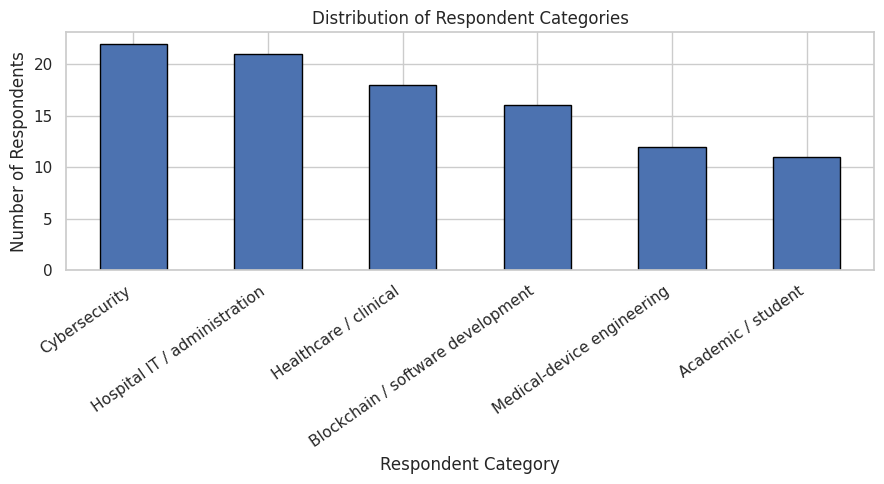

In [17]:
plt.figure(figsize=(9, 5))

respondent_frequency.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Respondent Categories")
plt.xlabel("Respondent Category")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig("respondent_distribution.png", dpi=300)
plt.show()

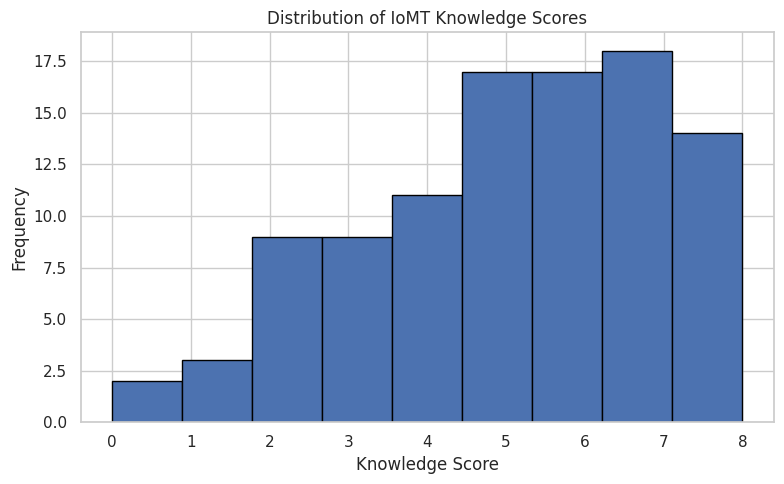

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Knowledge_score"].dropna(),
    bins=9,
    edgecolor="black"
)

plt.title("Distribution of IoMT Knowledge Scores")
plt.xlabel("Knowledge Score")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("knowledge_distribution.png", dpi=300)
plt.show()

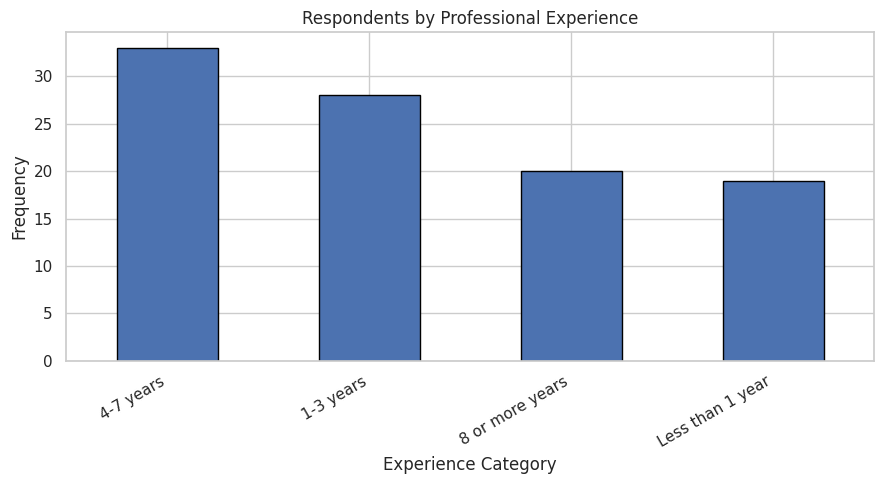

In [19]:
plt.figure(figsize=(9, 5))

readable["D2"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Respondents by Professional Experience")
plt.xlabel("Experience Category")
plt.ylabel("Frequency")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.savefig("experience_distribution.png", dpi=300)
plt.show()

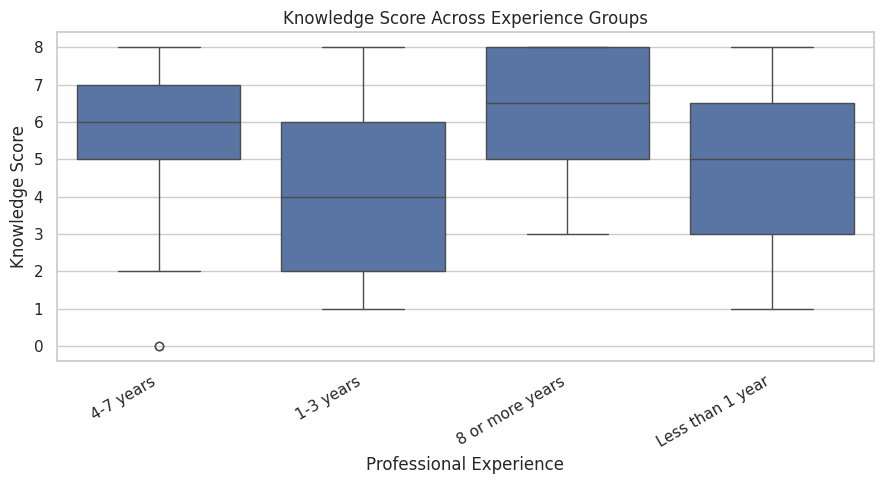

In [20]:
plot_data = readable[["D2"]].copy()

plot_data["Knowledge_score"] = (
    df["Knowledge_score"].to_numpy()
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=plot_data,
    x="D2",
    y="Knowledge_score"
)

plt.title("Knowledge Score Across Experience Groups")
plt.xlabel("Professional Experience")
plt.ylabel("Knowledge Score")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.savefig("knowledge_by_experience.png", dpi=300)
plt.show()

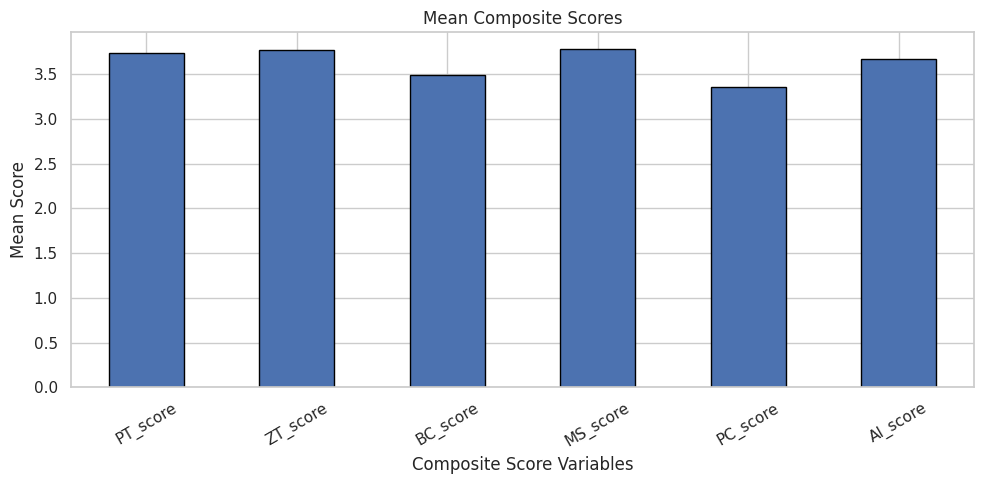

In [21]:
plt.figure(figsize=(10, 5))

df[score_columns].mean().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Mean Composite Scores")
plt.xlabel("Composite Score Variables")
plt.ylabel("Mean Score")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("composite_scores.png", dpi=300)
plt.show()

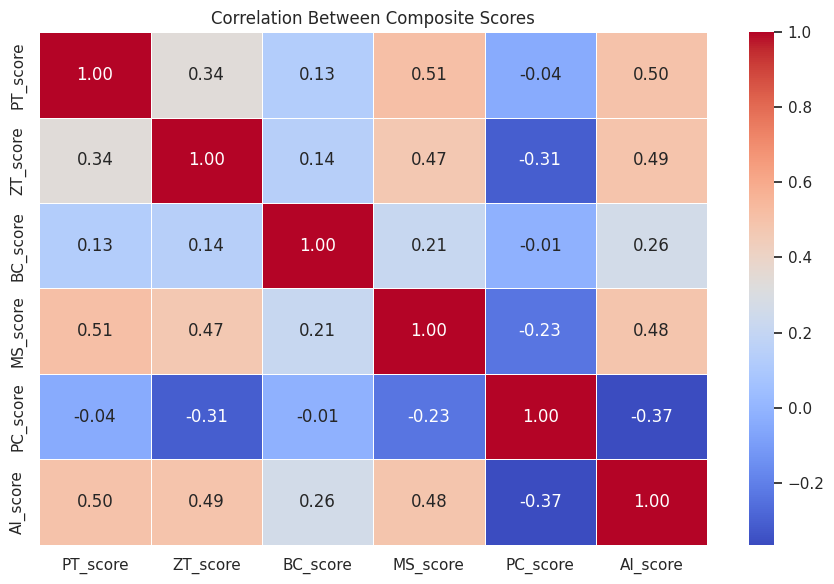

In [22]:
plt.figure(figsize=(9, 6))

correlation = df[score_columns].corr(
    method="spearman"
)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Composite Scores")

plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

In [23]:
prefixes = [
    "P1__",
    "P2__",
    "T1__",
    "M1__",
    "A1__",
    "B1__"
]

multiple_response_results = {}

for prefix in prefixes:

    columns = [
        col for col in df.columns
        if col.startswith(prefix)
    ]

    if columns:

        counts = (
            df[columns]
            .fillna(0)
            .sum()
            .sort_values(ascending=False)
        )

        multiple_response_results[prefix] = counts

        print("\nResults for:", prefix)
        display(counts.to_frame("Selection_Count"))


Results for: P1__


,Selection_Count
P1__Remote_patient_monitoring,42.0
P1__Wearable_monitors,39.0
P1__Infusion_pumps,32.0
P1__Smart_hospital_beds,29.0
P1__Connected_imaging_equipment,24.0
P1__Implantable_devices,18.0



Results for: P2__


,Selection_Count
P2__Passwords_PIN,53.0
P2__Device_certificates_PKI,36.0
P2__Network_segmentation,36.0
P2__Multi_factor_authentication,33.0
P2__Zero_trust_architecture,15.0
P2__Blockchain_based_logging,13.0
P2__Post_quantum_cryptography,5.0
P2__None_of_these,4.0



Results for: T1__


,Selection_Count
T1__Unauthorized_device_access,67
T1__Patient_data_breach,66
T1__Firmware_tampering,56
T1__Ransomware,47
T1__Insider_misuse,38
T1__Quantum_attack_on_cryptograp,34
T1__Denial_of_service,32


... (2 outputs left out)


Results for: A1__


,Selection_Count
A1__Firmware_update,74
A1__Access_to_a_full_patient_rec,62
A1__Change_of_device_configurati,55
A1__Change_of_therapy_parameters,55
A1__Emergency_override_break_gla,51
A1__Adding_a_new_device_to_the_n,41



Results for: B1__


,Selection_Count
B1__Cost,66
B1__Lack_of_skills,59
B1__Regulatory_uncertainty,52
B1__Performance_limits,47
B1__Interoperability_with_legacy,44
B1__Lack_of_standards,41
B1__Privacy_concerns,37


In [24]:
# Export descriptive statistics
descriptive_table.to_csv(
    "descriptive_statistics.csv"
)

# Export inferential test results
test_results = pd.DataFrame([
    {
        "Test": "Kruskal-Wallis",
        "Statistic": kw_stat,
        "P_Value": kw_p_value
    },
    {
        "Test": "Spearman Correlation",
        "Statistic": rho,
        "P_Value": spearman_p_value
    }
])

test_results.to_csv(
    "inferential_statistics.csv",
    index=False
)

# Export respondent distribution
respondent_table.to_csv(
    "respondent_distribution.csv"
)

print("Statistical results exported successfully!")

Statistical results exported successfully!


In [25]:
print("=" * 50)
print("FINAL STATISTICAL RESULTS")
print("=" * 50)

print("\n1. DATASET INFORMATION")
print("Total respondents:", len(df))
print("Total variables:", len(df.columns))

print("\n2. KNOWLEDGE SCORE")
print(df["Knowledge_score"].describe())

print("\n3. DESCRIPTIVE STATISTICS")
display(descriptive_table.round(3))

print("\n4. KRUSKAL-WALLIS TEST")
print("H-statistic:", kw_stat)
print("P-value:", kw_p_value)

print("\n5. SPEARMAN CORRELATION")
print("Correlation coefficient:", rho)
print("P-value:", spearman_p_value)

print("\n6. RESPONDENT DISTRIBUTION")
display(respondent_table)

FINAL STATISTICAL RESULTS

1. DATASET INFORMATION
Total respondents: 100
Total variables: 117

2. KNOWLEDGE SCORE
count    100.000000
mean       5.170000
std        2.103652
min        0.000000
25%        4.000000
50%        5.000000
75%        7.000000
max        8.000000
Name: Knowledge_score, dtype: float64

3. DESCRIPTIVE STATISTICS


,count,mean,std,median,min,max,IQR
PT_score,100.0,3.730,0.628,3.667,2.333,5.000,1.000
ZT_score,100.0,3.767,0.629,3.667,2.333,5.000,1.000
BC_score,100.0,3.490,0.553,3.333,2.000,4.667,1.000
MS_score,100.0,3.777,0.742,3.667,1.667,5.000,1.000
PC_score,100.0,3.353,0.595,3.333,2.000,4.667,0.667
AI_score,100.0,3.670,0.699,3.667,1.667,5.000,1.000



4. KRUSKAL-WALLIS TEST
H-statistic: 12.490319336276917
P-value: 0.005879080415432695

5. SPEARMAN CORRELATION
Correlation coefficient: 0.31391735254712394
P-value: 0.0014701661000131362

6. RESPONDENT DISTRIBUTION


,Frequency,Percentage
D1,,
Cybersecurity,22,22.0
Hospital IT / administration,21,21.0
Healthcare / clinical,18,18.0
Blockchain / software development,16,16.0
Medical-device engineering,12,12.0
Academic / student,11,11.0


In [26]:
!pip install scikit-posthocs

import scikit_posthocs as sp

# 1. Print and save the correlation matrix
correlation = df[score_columns].corr(method="spearman")

print("Spearman Correlation Matrix:")
display(correlation.round(3))

correlation.to_csv("composite_correlation_matrix.csv")

# 2. Dunn's post-hoc test
posthoc_data = readable[["D2"]].copy()
posthoc_data["Knowledge_score"] = df["Knowledge_score"].values

dunn_results = sp.posthoc_dunn(
    posthoc_data,
    val_col="Knowledge_score",
    group_col="D2",
    p_adjust="bonferroni"
)

print("Dunn's post-hoc test with Bonferroni correction:")
display(dunn_results.round(4))

dunn_results.to_csv("dunn_posthoc_results.csv")

Spearman Correlation Matrix:


,PT_score,ZT_score,BC_score,MS_score,PC_score,AI_score
PT_score,1.000,0.337,0.127,0.510,-0.043,0.498
ZT_score,0.337,1.000,0.142,0.469,-0.310,0.489
BC_score,0.127,0.142,1.000,0.212,-0.014,0.262
MS_score,0.510,0.469,0.212,1.000,-0.233,0.484
PC_score,-0.043,-0.310,-0.014,-0.233,1.000,-0.365
AI_score,0.498,0.489,0.262,0.484,-0.365,1.000


Dunn's post-hoc test with Bonferroni correction:


,1-3 years,4-7 years,8 or more years,Less than 1 year
1-3 years,1.0000,0.0781,0.0094,1.0000
4-7 years,0.0781,1.0000,1.0000,0.7866
8 or more years,0.0094,1.0000,1.0000,0.1450
Less than 1 year,1.0000,0.7866,0.1450,1.0000


In [27]:
experience_summary = (
    posthoc_data.groupby("D2")["Knowledge_score"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

display(experience_summary)

,count,mean,median,std
D2,,,,
1-3 years,28,4.286,4.0,2.070
4-7 years,33,5.545,6.0,2.048
8 or more years,20,6.200,6.5,1.765
Less than 1 year,19,4.737,5.0,2.077
